In [1]:
# -----------------------------------------------------------------------
# Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import skew, spearmanr,qmc
from scipy.optimize import minimize
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



n = 42 (30 initial + 12 queried); newest x = [0.       0.182729 0.44828  0.293988 0.330598 0.624573], y = 2.773936
best observed: row 41, x = [0.       0.182729 0.44828  0.293988 0.330598 0.624573], y = 2.773936; previous best 2.754623 (row 40); gain +0.0193
step from the previous best to the newest point: [ 0.     -0.0171  0.0234 -0.0109  0.0033 -0.0165] (length 0.035)




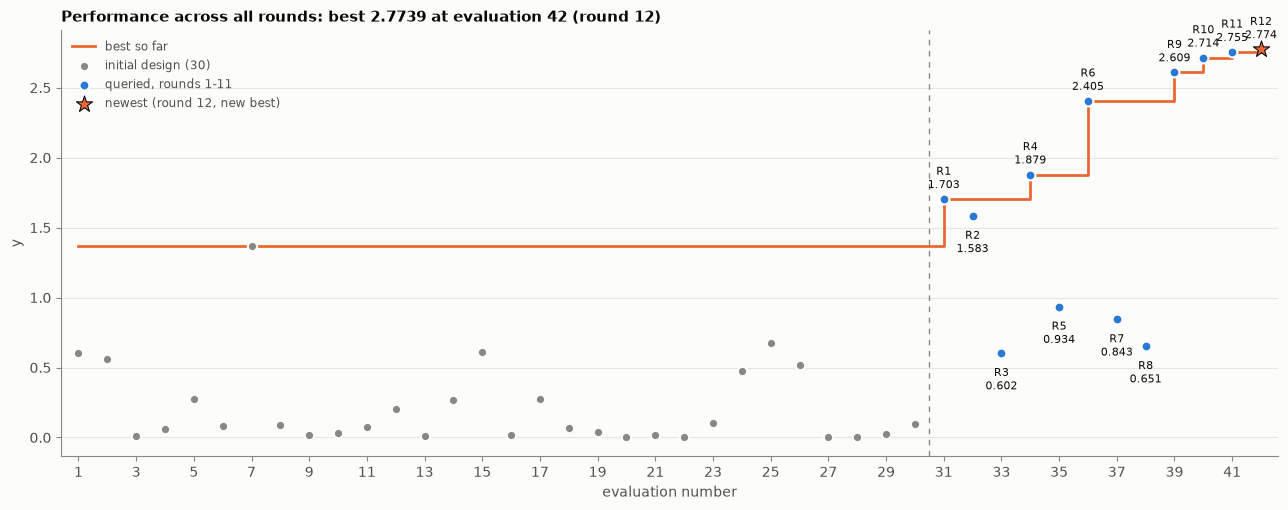

In [2]:
# -----------------------------------------------------------------------
# DATA
# -----------------------------------------------------------------------
X = np.load('..\Function_7_Data\Week_13_Data/F7_Week_13_inputs.npy')
y = np.load('..\Function_7_Data\Week_13_Data/F7_Week_13_outputs.npy')
n, d = X.shape
N_INITIAL = 30
NEW = n - 1
best = int(np.argmax(y))
xb = X[best]
prev_best = int(np.argmax(y[:NEW]))
xb_prev = X[prev_best]
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[NEW], 6)}, y = {y[NEW]:.6f}")
print(f"best observed: row {best}, x = {np.round(xb, 6)}, y = {y[best]:.6f}; previous best {y[prev_best]:.6f} (row {prev_best}); "
      f"gain {y[best] - y[prev_best]:+.4f}")
print(f"step from the previous best to the newest point: {np.round(X[NEW] - xb_prev, 4)} (length {np.linalg.norm(X[NEW] - xb_prev):.3f})")
print('\n')

# Fig 1: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, ax = plt.subplots(figsize=(13, 5.2))
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=PAL[1], lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=45, color=MUTED, edgecolor=SURFACE, linewidth=1.5,
           label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:NEW], y[N_INITIAL:NEW], s=50, color=PAL[0], edgecolor=SURFACE, linewidth=1.5,
           label=f"queried, rounds 1-{n - N_INITIAL - 1}", zorder=3)
ax.scatter(idx[NEW], y[NEW], s=150, marker="*", color=PAL[1], edgecolor=INK, linewidth=0.8, zorder=4,
           label=f"newest (round {n - N_INITIAL}" + (", new best)" if NEW == best else ")"))
for i in range(N_INITIAL, n):
    ax.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.3f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] - 1e-12 else -26),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_xticks(idx[::2]); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False)
ax.set_xlabel("evaluation number"); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {y.max():.4f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="upper left", fontsize=8.5, labelcolor=INK2)
fig.tight_layout()

  skew of log  target: -0.39
  skew of sqrt target: +0.71
  skew of raw  target: +1.38


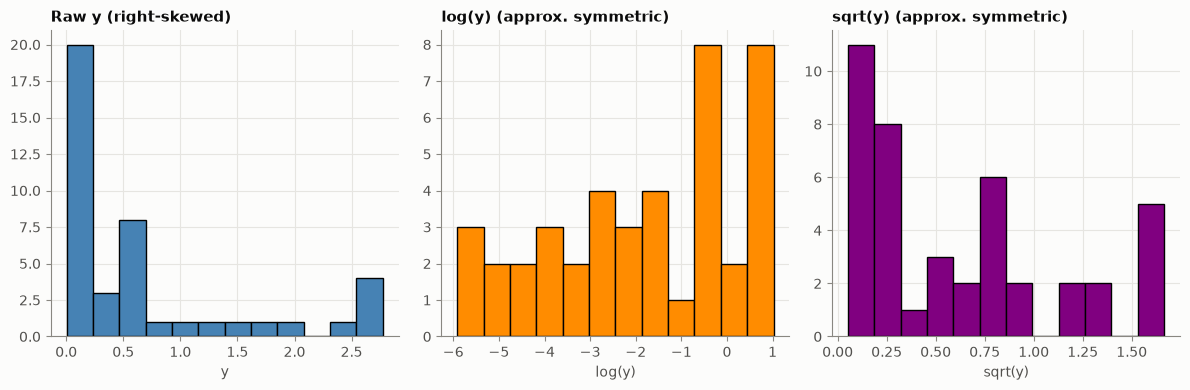

In [3]:
# -----------------------------------------------------------------------
# DATA TRANSFORMATION 
# -----------------------------------------------------------------------

TRANSFORMS = {"log": (np.log, np.exp),
              "sqrt": (np.sqrt, lambda m: np.maximum(m, 0) ** 2),
              "raw": (lambda v: v.copy(), lambda m: m)}
for k, (f, _) in TRANSFORMS.items():
    print(f"  skew of {k:4s} target: {skew(f(y)):+.2f}")

# Fig 2: target transforms
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].hist(y, bins=12, color="steelblue", edgecolor="k")
axes[0].set_title("Raw y (right-skewed)")
axes[0].set_xlabel("y")
axes[1].hist(np.log(y), bins=12, color="darkorange", edgecolor="k")
axes[1].set_title("log(y) (approx. symmetric)")
axes[1].set_xlabel("log(y)")
axes[2].hist(np.sqrt(y), bins=12, color="purple", edgecolor="k")
axes[2].set_title("sqrt(y) (approx. symmetric)")
axes[2].set_xlabel("sqrt(y)")
plt.tight_layout()


MODELS (LOO with hyperparameters fixed; raw-y errors for the best 6 points)
  log-ARD  ls=[1.62 1.37 1.03 0.64 0.58 0.89]  noise var (normalised)=1.0e-06  RMSE/std(own)=0.452  Spearman=0.905  95% cover=0.93  top-6 raw RMSE=0.022
  log-iso  ls=[0.79]  noise var (normalised)=1.0e-06  RMSE/std(own)=0.489  Spearman=0.901  95% cover=1.00  top-6 raw RMSE=0.059
  sqrt-ARD ls=[1.42 0.95 1.88 0.52 0.38 0.48]  noise var (normalised)=1.0e-06  RMSE/std(own)=0.247  Spearman=0.937  95% cover=1.00  top-6 raw RMSE=0.022
  sqrt-iso ls=[0.56]  noise var (normalised)=1.0e-06  RMSE/std(own)=0.360  Spearman=0.884  95% cover=1.00  top-6 raw RMSE=0.026
  raw-ARD  ls=[0.81 0.71 1.17 0.39 0.25 0.33]  noise var (normalised)=3.3e-05  RMSE/std(own)=0.219  Spearman=0.866  95% cover=1.00  top-6 raw RMSE=0.020
  raw-iso  ls=[0.4]  noise var (normalised)=1.0e-06  RMSE/std(own)=0.311  Spearman=0.784  95% cover=1.00  top-6 raw RMSE=0.038




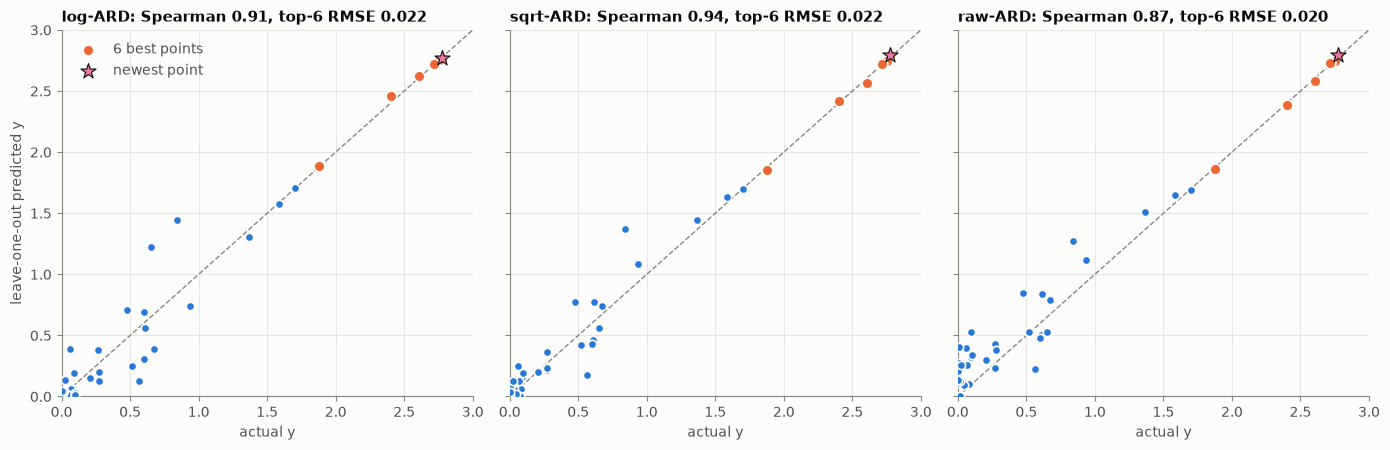

In [4]:
#-----------------------------------------------------------------------
# Models
#-----------------------------------------------------------------------


def fit(Xf, t, ard):
    k = (ConstantKernel(1.0, (1e-2, 1e3)) * Matern(length_scale=np.ones(d) if ard else 1.0,
                                      length_scale_bounds=(1e-2, 1e2), nu=2.5)
         + WhiteKernel(1e-2, (1e-6, 1.0)))
    return GaussianProcessRegressor(kernel=k, normalize_y=True, n_restarts_optimizer=25,
                                    random_state=SEED).fit(Xf, t)

top = np.argsort(-y)[:6]
models, loos = {}, {}
print("\nMODELS (LOO with hyperparameters fixed; raw-y errors for the best 6 points)")
for tname, (f, back) in TRANSFORMS.items():
    t = f(y)
    for ard in (True, False):
        key = f"{tname}-{'ARD' if ard else 'iso'}"
        gp = fit(X, t, ard)
        mu, sd = np.empty(n), np.empty(n)
        for i in range(n):
            keep = np.arange(n) != i
            g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True).fit(X[keep], t[keep])
            a, s = g.predict(X[i:i + 1], return_std=True)
            mu[i], sd[i] = a[0], s[0]
        models[key] = (gp, back)
        loos[key] = back(mu)
        ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
        print(f"  {key:8s} ls={np.round(ls, 2)}  noise var (normalised)={gp.kernel_.k2.noise_level:.1e}  "
              f"RMSE/std(own)={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
              f"Spearman={spearmanr(y, loos[key])[0]:.3f}  95% cover={np.mean(np.abs((t - mu) / sd) < 1.96):.2f}  "
              f"top-6 raw RMSE={np.sqrt(np.mean((y[top] - loos[key][top]) ** 2)):.3f}")
KEYS = list(models)

def pred(key, Z):
    g, back = models[key]
    return back(g.predict(np.atleast_2d(Z)))

print('\n')
# Fig 3: LOO for the three ARD models, raw y
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
lim = [0, 3]
for ax, key in zip(axes, ["log-ARD", "sqrt-ARD", "raw-ARD"]):
    yb = loos[key]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y, yb, s=36, color=PAL[0], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[top], yb[top], s=60, color=PAL[1], edgecolor=SURFACE, linewidth=1.2, zorder=4, label="6 best points")
    ax.scatter(y[NEW], yb[NEW], s=130, marker="*", color=PAL[4], edgecolor=INK, linewidth=0.8, zorder=5, label="newest point")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("actual y")
    ax.set_title(f"{key}: Spearman {spearmanr(y, yb)[0]:.2f}, top-6 RMSE {np.sqrt(np.mean((y[top] - yb[top]) ** 2)):.3f}")
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()


WEEK-12 PREDICTIONS at the newest point (models refitted on the first 41 rows); observed 2.7739
  log-ARD   predicted 2.7708   error +0.0032   z (transformed) +0.04
  log-iso   predicted 2.7467   error +0.0272   z (transformed) +0.29
  sqrt-ARD  predicted 2.7939   error -0.0200   z (transformed) -0.72
  sqrt-iso  predicted 2.7775   error -0.0036   z (transformed) -0.11
  raw-ARD   predicted 2.8017   error -0.0278   z (transformed) -1.33
  raw-iso   predicted 2.7774   error -0.0035   z (transformed) -0.15




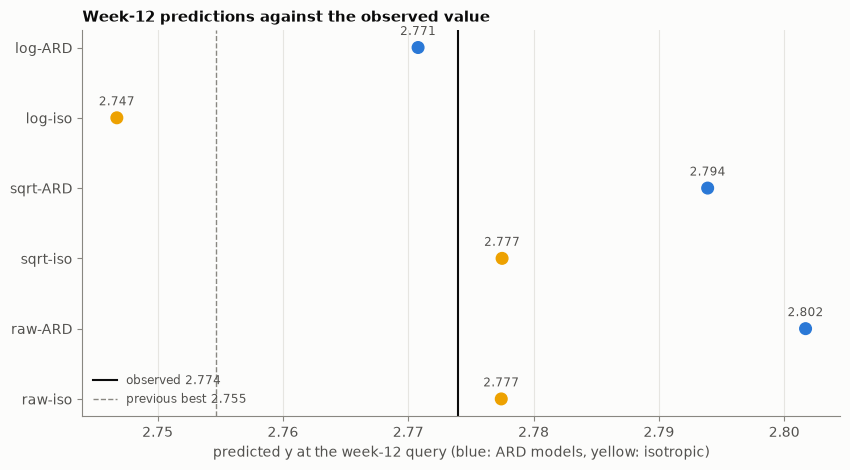

In [5]:
# ---------------------------------------------------------------- 
# Week-12 predictions at the newest point
# ---------------------------------------------------------------- 
print(f"\nWEEK-12 PREDICTIONS at the newest point (models refitted on the first {NEW} rows); observed {y[NEW]:.4f}")
prev_pred = {}
for key in KEYS:
    tname, kind = key.split("-")
    f, back = TRANSFORMS[tname]
    g = fit(X[:NEW], f(y[:NEW]), kind == "ARD")
    m, s = g.predict(X[NEW:NEW + 1], return_std=True)
    zt = (f(y[NEW:NEW + 1])[0] - m[0]) / s[0]
    prev_pred[key] = back(m)[0]
    print(f"  {key:9s} predicted {back(m)[0]:.4f}   error {y[NEW] - back(m)[0]:+.4f}   z (transformed) {zt:+.2f}")

print('\n')
# Fig 2: week-12 predictions vs outcome
fig, ax = plt.subplots(figsize=(8.6, 4.8))
names = KEYS
vals = [prev_pred[k] for k in names]
ypos = np.arange(len(names))[::-1]
cols = [PAL[0] if "ARD" in k else PAL[3] for k in names]
ax.scatter(vals, ypos, s=70, color=cols, zorder=3)
for v_, p_ in zip(vals, ypos):
    ax.annotate(f"{v_:.3f}", (v_, p_), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax.axvline(y[NEW], color=INK, lw=1.5, label=f"observed {y[NEW]:.3f}")
ax.axvline(y[prev_best], color=MUTED, lw=1, ls="--", label=f"previous best {y[prev_best]:.3f}")
ax.set_yticks(ypos); ax.set_yticklabels(names)
ax.set_xlabel("predicted y at the week-12 query (blue: ARD models, yellow: isotropic)")
ax.set_title("Week-12 predictions against the observed value")
ax.legend(frameon=False, loc="lower left", fontsize=8.5, labelcolor=INK2)
ax.grid(axis="y", visible=False)
fig.tight_layout()


In [6]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 

S = qmc.Sobol(d, seed=1).random(2 ** 14)
def box_argmax(fn, r):
    lo, hi = np.clip(xb - r, 0, 1), np.clip(xb + r, 0, 1)
    Z = lo + S * (hi - lo); v = fn(Z); x0 = Z[v.argmax()]
    res = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return res.x if -res.fun >= v.max() else x0

base = {k: pred(k, xb)[0] for k in KEYS}
ens_gain = lambda Z: np.mean([pred(k, Z) - base[k] for k in KEYS], axis=0)
x_sqrt_box = box_argmax(lambda Z: models["sqrt-ARD"][0].predict(Z), 0.1)
x_log_box = box_argmax(lambda Z: models["log-ARD"][0].predict(Z), 0.1)
x_ens = box_argmax(ens_gain, 0.05)
x_cont = np.clip(xb + 0.5 * (xb - xb_prev), 0, 1)
# line search along the direction of the last step (newest point minus the previous best point)
steps = np.arange(-1.0, 4.01, 0.5)
dir1 = X[NEW] - X[prev_best]
print("\nLINE SEARCH from the best point along the last-step direction (s in units of that step)")
print("    s   " + "  ".join(f"{k:>8s}" for k in KEYS) + "      mean")
for s_ in steps:
    z = np.clip(xb + s_ * dir1, 0, 1)
    gv = np.array([pred(k, z)[0] - base[k] for k in KEYS])
    print(f"  {s_:+.1f}  " + "  ".join(f"{v:+8.3f}" for v in gv) + f"   {gv.mean():+.4f}")
fine = np.arange(0, 2.001, 0.05)
s_best = fine[int(np.argmax([np.mean([pred(k, np.clip(xb + q * dir1, 0, 1))[0] - base[k] for k in KEYS]) for q in fine]))]
x_line = np.clip(xb + s_best * dir1, 0, 1)  # equals the best point when the ensemble peaks at s = 0
print(f"\n  Ensemble-mean maximum on 0..2 steps: s = {s_best:.2f}  x = {np.round(x_line, 6)}")
cands = {
    "A: highest mean, sqrt-ARD (+/-0.1)": x_sqrt_box,
    "B: half-step towards A": xb + 0.5 * (x_sqrt_box - xb),
    "C: highest mean, log-ARD (+/-0.1)": x_log_box,
    "D: continue last step (half)": x_cont,
    "E: ensemble-mean max (+/-0.05)": x_ens,
    "F: stay at best (control)": x_line,
}
gains = {}
print("\nCANDIDATES: predicted y by each model; gain = prediction minus the same model's prediction at the best point")
print("  reference at the best point: " + "  ".join(f"{k}={v:.3f}" for k, v in base.items()) + f"   (observed {y.max():.4f})")
for name, xc in cands.items():
    p = {k: pred(k, xc)[0] for k in KEYS}
    gains[name] = {k: p[k] - base[k] for k in KEYS}
    print(f"  {name:42s} x = ({', '.join(f'{v:.6f}' for v in xc)})  dist {np.linalg.norm(xc - xb):.3f}")
    print("      predicted: " + "  ".join(f"{k}={v:.3f}" for k, v in p.items()))
    print("      gain     : " + "  ".join(f"{k}={v:+.3f}" for k, v in gains[name].items())
          + f"   mean {np.mean(list(gains[name].values())):+.4f}   models predicting a gain: {sum(v > 0 for v in gains[name].values())} of 6")

# probability that each candidate beats the best observed value (predictive sd, transformed space)
from scipy.stats import norm
print("\nP(y > best observed) by model and candidate")
for name, xc in cands.items():
    pv = []
    for key in KEYS:
        g, back = models[key]
        f = TRANSFORMS[key.split("-")[0]][0]
        m_, s_ = g.predict(np.atleast_2d(xc), return_std=True)
        pv.append(1 - norm.cdf((f(np.array([y.max()]))[0] - m_[0]) / s_[0]))
    print(f"  {name:42s} " + "  ".join(f"{k}={v:.2f}" for k, v in zip(KEYS, pv)) + f"   mean {np.mean(pv):.2f}")



LINE SEARCH from the best point along the last-step direction (s in units of that step)
    s    log-ARD   log-iso  sqrt-ARD  sqrt-iso   raw-ARD   raw-iso      mean
  -1.0    -0.019    -0.019    -0.020    -0.019    -0.023    -0.019   -0.0200
  -0.5    -0.003    -0.002    -0.006    -0.003    -0.008    -0.004   -0.0042
  +0.0    +0.000    +0.000    +0.000    +0.000    +0.000    +0.000   +0.0000
  +0.5    -0.012    -0.014    -0.002    -0.009    +0.001    -0.008   -0.0074
  +1.0    -0.038    -0.044    -0.012    -0.031    -0.005    -0.027   -0.0261
  +1.5    -0.079    -0.090    -0.028    -0.064    -0.016    -0.057   -0.0558
  +2.0    -0.132    -0.152    -0.052    -0.107    -0.034    -0.096   -0.0956
  +2.5    -0.198    -0.227    -0.082    -0.161    -0.057    -0.144   -0.1449
  +3.0    -0.275    -0.314    -0.119    -0.224    -0.086    -0.199   -0.2026
  +3.5    -0.361    -0.412    -0.161    -0.294    -0.118    -0.261   -0.2678
  +4.0    -0.455    -0.518    -0.208    -0.371    -0.156    -0.3